# H4b Polaryzacja językowa (trafność klasyfikacji obozów)

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from tqdm.auto import tqdm

from src.config import (CAMP_TERMS, CYCLES, H4B_PER_CELL, H4B_PHASES, H4B_REPEATS, POLITICAL_SUBREDDITS, PROCESSED_DIR,
                        RANDOM_STATE, RESULTS_DIR)
from src.terms import mask_terms

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SHUFFLE_REPEATS = 20
LEAK_HINTS = ["democrats", "liberal", "republican", "conservative", "flair", "mods", "removed", "rule"]
CELLS = ["subreddit", "phase"]

c:\Users\karol\Licencjat_programowanie\Licencjat\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print(CAMP_TERMS)

{'dem': {'party': ['democrat', 'democrats', 'dem', 'dems', 'dnc', 'liberals'], 'politician': ['obama', 'barack', 'biden', 'clinton', 'hillary', 'kaine', 'harris', 'kamala', 'walz']}, 'rep': {'party': ['republican', 'republicans', 'gop', 'rnc', 'conservatives'], 'politician': ['romney', 'mitt', 'ryan', 'trump', 'pence', 'vance']}}


In [3]:
CAMP_TERMS = {
    "dem": {"party": ["democrat", "democrats", "dem", "dems", "dnc", "liberals"],
            "politician": ["obama", "barack", "biden", "clinton", "hillary", "kaine", "harris", "kamala", "walz"]},
    "rep": {"party": ["republican", "republicans", "gop", "rnc", "conservatives"],
            "politician": ["romney", "mitt", "ryan", "trump", "pence", "vance"]},
}

## 2. Dane: subreddity polityczne, fazy szczytowa i przejściowa, po maskowaniu

In [4]:
assert any(CAMP_TERMS[camp][term_type] for camp in CAMP_TERMS for term_type in CAMP_TERMS[camp]), "CAMP_TERMS jest pusty"
sample = pd.read_parquet(PROCESSED_DIR / "sample.parquet", columns=["id", "link_id", "subreddit", "camp", "cycle", "phase", "text"])
data = sample[sample["subreddit"].isin(POLITICAL_SUBREDDITS) & sample["phase"].isin(H4B_PHASES)].reset_index(drop=True)
data["text"] = mask_terms(data["text"], CAMP_TERMS)
cell_sizes = data.groupby(["subreddit", "phase", "cycle"]).size().unstack("cycle")
cell_sizes

cycle                     2012  2016  2020  2024
subreddit    phase                              
Conservative przejsciowa  3300  3300  3300  3300
             szczytowa    2700  4800  3000  3300
Liberal      przejsciowa  3032  3300  3182  3300
             szczytowa    2044  4062  3000  3162
Republican   przejsciowa  3300  3300  3241  3300
             szczytowa    2700  4800  2987  3300
democrats    przejsciowa  1848  3300  3300  3300
             szczytowa    1810  4584  3000  3300

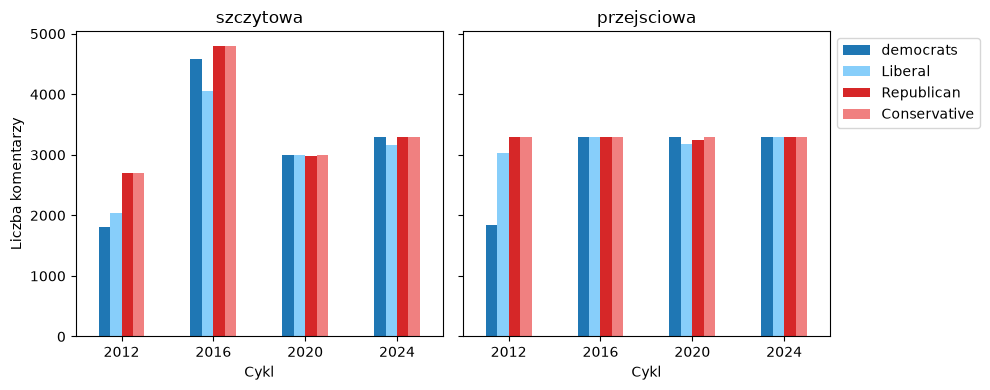

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, phase in zip(axes, H4B_PHASES):
    (cell_sizes.xs(phase, level="phase").loc[POLITICAL_SUBREDDITS].T
     .plot.bar(ax=ax, rot=0, legend=False, color=["tab:blue", "lightskyblue", "tab:red", "lightcoral"]))
    ax.set_title(phase)
    ax.set_xlabel("Cykl")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
axes[0].set_ylabel("Liczba komentarzy")
plt.tight_layout()
plt.show()

## 3. Wspólna liczebność: 80% najmniejszej komórki

In [6]:
per_cell = H4B_PER_CELL or int(0.8 * cell_sizes.min().min())
print("komentarzy na komórkę:", per_cell, "| na cykl:", 8 * per_cell)

komentarzy na komórkę: 1448 | na cykl: 11584


## 4. Model i powtórzenia (losowanie próby + walidacja krzyżowa po wątkach)

In [7]:
model = make_pipeline(TfidfVectorizer(stop_words="english", min_df=5), LogisticRegression(max_iter=1000))
rows = []
for repetition in tqdm(range(H4B_REPEATS)):
    for cycle in CYCLES:
        part = data[data["cycle"] == cycle].groupby(CELLS).sample(per_cell, random_state=repetition)
        predicted = cross_val_predict(model, part["text"], part["camp"], cv=GroupKFold(n_splits=5), groups=part["link_id"], n_jobs=-1)
        correct = predicted == part["camp"]
        rows.append({"cycle": cycle, "repetition": repetition,
                     "acc_dem": correct[part["camp"] == "dem"].mean(), "acc_rep": correct[part["camp"] == "rep"].mean()})
repeats = pd.DataFrame(rows)
repeats["accuracy"] = (repeats["acc_dem"] + repeats["acc_rep"]) / 2
repeats.to_csv(RESULTS_DIR / "h4b_repeats.csv", index=False)
repeats.head()

100%|██████████| 100/100 [06:11<00:00,  3.72s/it]


,cycle,repetition,acc_dem,acc_rep,accuracy
0,2012,0,0.551278,0.585635,0.568456
1,2016,0,0.578384,0.594613,0.586499
2,2020,0,0.564227,0.593405,0.578816
3,2024,0,0.592023,0.611706,0.601865
4,2012,1,0.553522,0.597030,0.575276


## 5. Kontrola przecieku: przemieszane etykiety obozów

In [8]:
rows = []
for repetition in tqdm(range(SHUFFLE_REPEATS)):
    for cycle in CYCLES:
        part = data[data["cycle"] == cycle].groupby(CELLS).sample(per_cell, random_state=repetition)
        shuffled = part["camp"].sample(frac=1, random_state=repetition).to_numpy()
        predicted = cross_val_predict(model, part["text"], shuffled, cv=GroupKFold(n_splits=5), groups=part["link_id"], n_jobs=-1)
        rows.append({"cycle": cycle, "repetition": repetition, "accuracy": (predicted == shuffled).mean()})
shuffled_accuracy = pd.DataFrame(rows)
shuffled_accuracy.to_csv(RESULTS_DIR / "h4b_shuffled.csv", index=False)
shuffled_accuracy.groupby("cycle")["accuracy"].mean().round(4)

100%|██████████| 20/20 [01:02<00:00,  3.12s/it]


cycle
2012    0.5005
2016    0.4985
2020    0.4985
2024    0.4998
Name: accuracy, dtype: float64

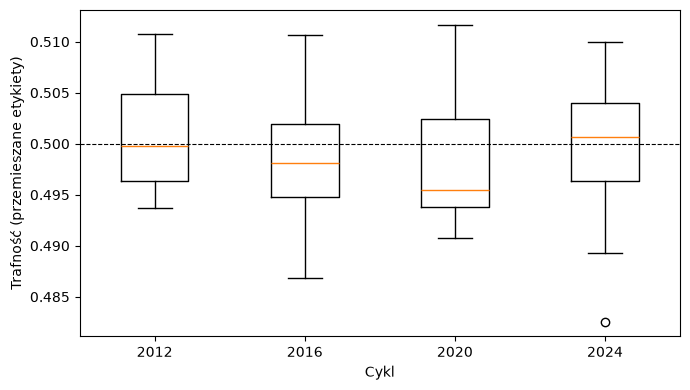

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([shuffled_accuracy[shuffled_accuracy["cycle"] == cycle]["accuracy"] for cycle in CYCLES], tick_labels=CYCLES)
ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("Cykl")
ax.set_ylabel("Trafność (przemieszane etykiety)")
plt.tight_layout()
plt.show()

## 6. Wyniki dla cykli

In [10]:
summary = repeats.groupby("cycle")["accuracy"].agg(mean="mean", p2_5=lambda values: values.quantile(0.025),
                                                   p97_5=lambda values: values.quantile(0.975))
summary[["acc_dem", "acc_rep"]] = repeats.groupby("cycle")[["acc_dem", "acc_rep"]].mean()
summary.to_csv(RESULTS_DIR / "h4b_summary.csv")
summary.round(4)

,mean,p2_5,p97_5,acc_dem,acc_rep
cycle,,,,,
2012,0.5695,0.5592,0.5791,0.5524,0.5866
2016,0.5825,0.5726,0.5925,0.5717,0.5934
2020,0.5865,0.5774,0.5943,0.5834,0.5896
2024,0.5948,0.5830,0.6042,0.5892,0.6004


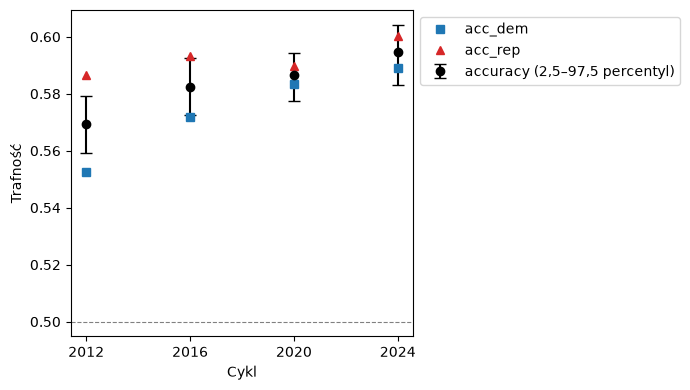

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(summary.index, summary["mean"], yerr=[summary["mean"] - summary["p2_5"], summary["p97_5"] - summary["mean"]],
            fmt="o", color="black", capsize=4, label="accuracy (2,5–97,5 percentyl)")
ax.plot(summary.index, summary["acc_dem"], "s", color="tab:blue", label="acc_dem")
ax.plot(summary.index, summary["acc_rep"], "^", color="tab:red", label="acc_rep")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
ax.set_xticks(summary.index)
ax.set_xlabel("Cykl")
ax.set_ylabel("Trafność")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [12]:
period = summary["mean"].groupby(lambda cycle: "2020+2024" if cycle >= 2020 else "2012+2016").mean()
period.to_csv(RESULTS_DIR / "h4b_period_comparison.csv")
period.round(4)

cycle
2012+2016    0.5760
2020+2024    0.5906
Name: mean, dtype: float64

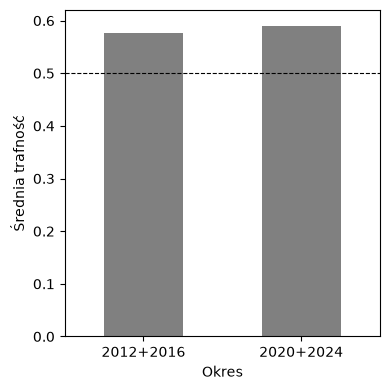

In [13]:
ax = period.plot.bar(figsize=(4, 4), rot=0, color="gray")
ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("Okres")
ax.set_ylabel("Średnia trafność")
plt.tight_layout()
plt.show()

## 7. Słowa wyróżniające (model dopasowany raz na próbie cyklu)

In [14]:
rows = []
for cycle in CYCLES:
    part = data[data["cycle"] == cycle].groupby(CELLS).sample(per_cell, random_state=RANDOM_STATE)
    model.fit(part["text"], part["camp"])
    assert list(model.classes_) == ["dem", "rep"]
    words = model[0].get_feature_names_out()
    coefficients = model[1].coef_[0]
    order = coefficients.argsort()
    for camp, indices in (("dem", order[:20]), ("rep", order[::-1][:20])):
        for rank, index in enumerate(indices, start=1):
            rows.append({"cycle": cycle, "camp": camp, "rank": rank, "word": words[index], "coef": coefficients[index],
                         "leak_hint": words[index] in LEAK_HINTS})
top_words = pd.DataFrame(rows)
top_words.to_csv(RESULTS_DIR / "h4b_top_words.csv", index=False)
top_words.pivot_table(index=["cycle", "rank"], columns="camp", values="word", aggfunc="first").head(40)

camp                 dem             rep
cycle rank                              
2012  1           banned          israel
      2             fuck        spending
      3              fox        decision
      4            fight             msm
      5              sad           based
      6           signed          europe
      7            white        politics
      8         facebook           fraud
      9             guns         polling
      10        convince        examples
      11         liberal       arguments
      12           right              vs
      13         arizona        huntsman
      14          bullet            hard
      15           drunk             yep
      16             war          belief
      17          little           point
      18         extreme           msnbc
      19             joe            cost
      20            wish          budget
2016  1           bernie            cruz
      2      progressive          kasich
      3          sanders    conservative
      4       democratic    conservatism
      5            stein           rubio
      6           lesser        abortion
      7             wing  constitutional
      8           booker         shapiro
      9           voters      principles
      10       corporate     immigration
      11    progressives      classified
      12         fucking      nevertrump
      13           fraud         leftist
      14          street             fly
      15           proud      difference
      16         selfish         subject
      17      philosophy          mccain
      18            lgbt            fine
      19        disagree   nevertrumpers
      20          energy        leftists

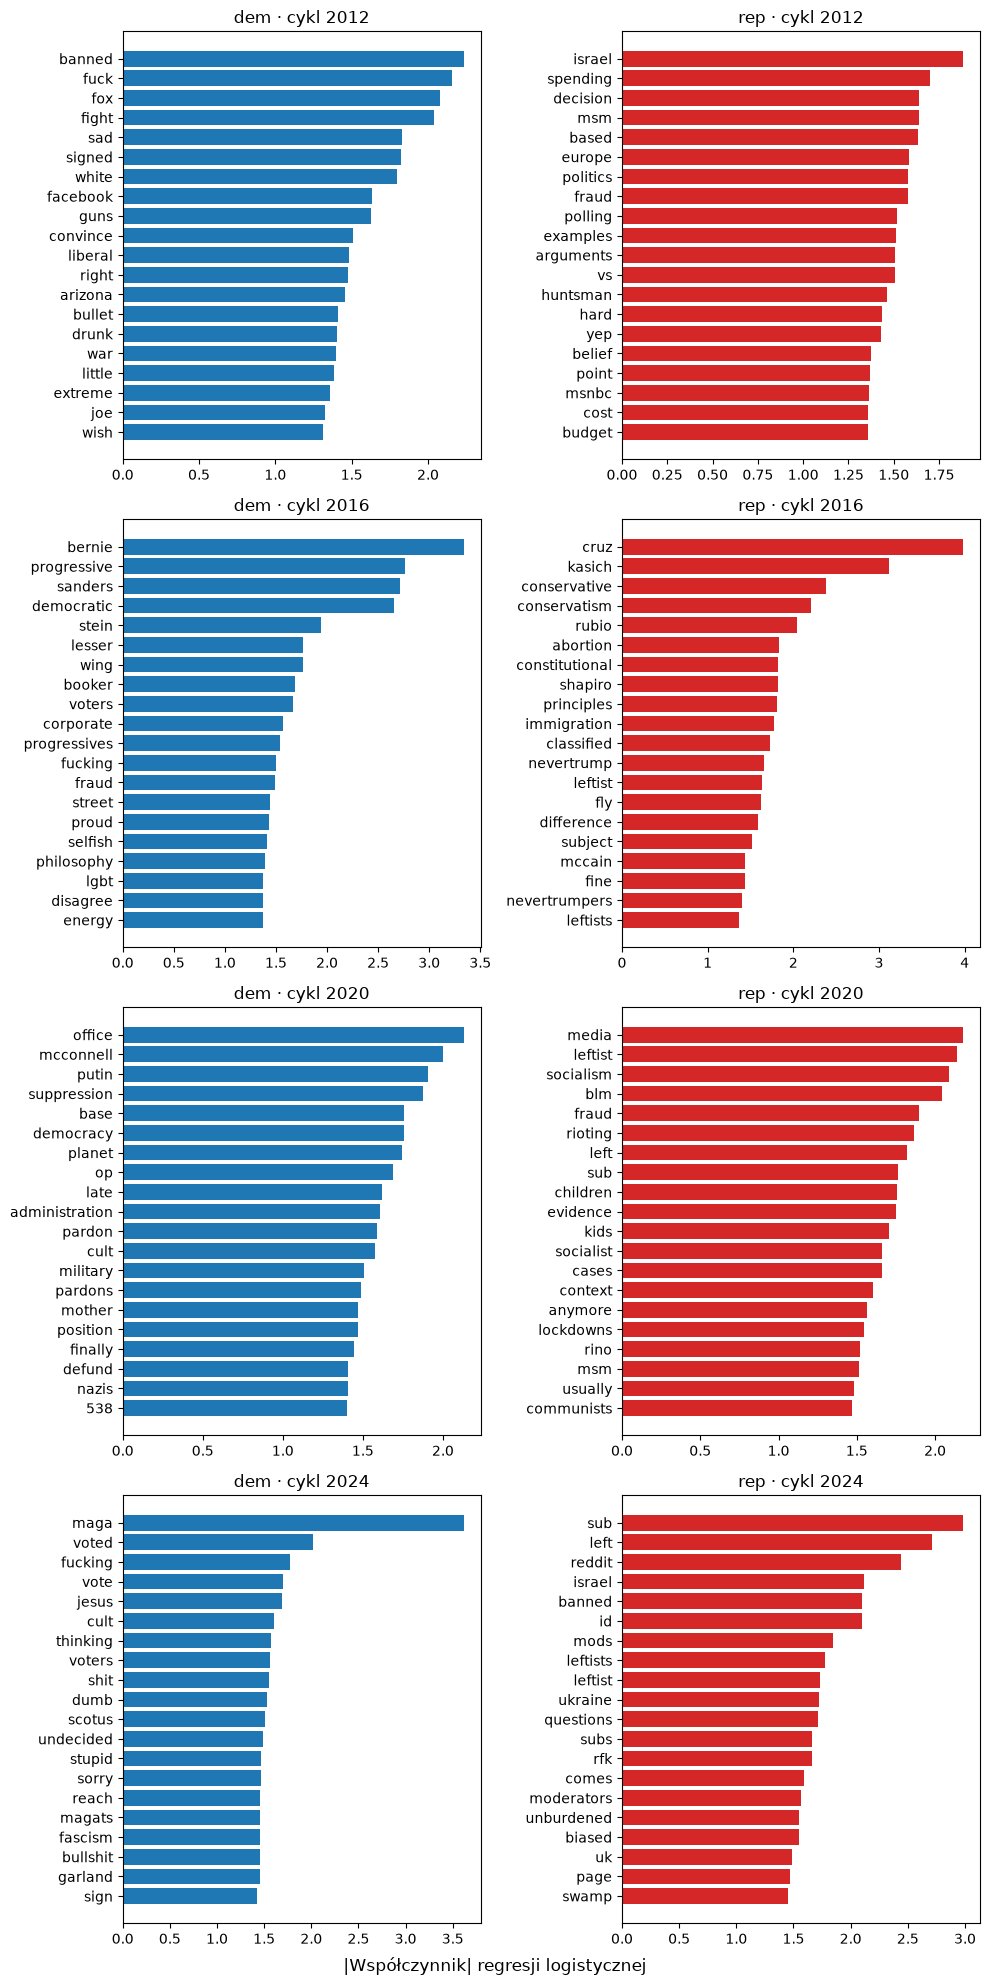

In [15]:
fig, axes = plt.subplots(len(CYCLES), 2, figsize=(10, 5 * len(CYCLES)))
for row, cycle in zip(axes, CYCLES):
    for ax, camp, color in zip(row, ["dem", "rep"], ["tab:blue", "tab:red"]):
        words = top_words[(top_words["cycle"] == cycle) & (top_words["camp"] == camp)]
        ax.barh(words["word"], words["coef"].abs(), color=color)
        ax.invert_yaxis()
        ax.set_title(f"{camp} · cykl {cycle}")
fig.supxlabel("|Współczynnik| regresji logistycznej")
plt.tight_layout()
plt.show()

In [16]:
top_words[top_words["leak_hint"]]

,cycle,camp,rank,word,coef,leak_hint
10,2012,dem,11,liberal,-1.480222,True
62,2016,rep,3,conservative,2.376052,True
146,2024,rep,7,mods,1.848230,True


## 8. Wykres roboczy

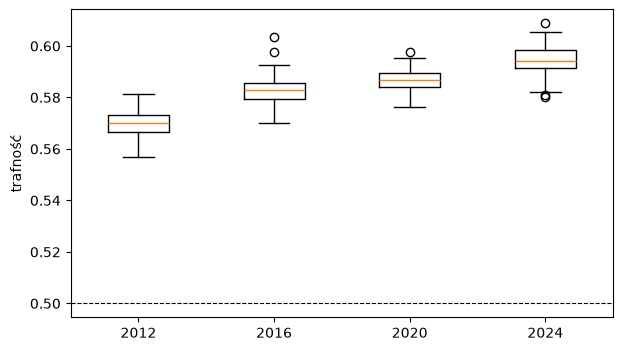

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([repeats[repeats["cycle"] == cycle]["accuracy"] for cycle in CYCLES], tick_labels=CYCLES)
ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8)
ax.set_ylabel("trafność")
plt.show()